Import necessary libraries & Pdf extraction

In [1]:

!pip -q install pymupdf tiktoken pandas

import fitz
import re
import json
from pathlib import Path
from google.colab import files

output_dir = Path("/content/slovakia_imf")
output_dir.mkdir(exist_ok=True)

uploaded = files.upload()
pdf_name = next((name for name in uploaded if name.lower().endswith(".pdf")), None)

if pdf_name is None:
    raise ValueError("Please upload the Slovakia IMF PDF.")

doc = fitz.open(pdf_name)
pages = []

def clean_text(text):
    text = text.replace("\u00ad", "")
    text = re.sub(r"(?<=\w)-\s*\n(?=\w)", "", text)

    lines = []
    for line in text.splitlines():
        line = line.strip()
        if not line:
            lines.append("")
            continue

        if re.fullmatch(r"\d+", line):
            continue
        if re.fullmatch(r"SLOVAK REPUBLIC", line, re.I):
            continue
        if "©International Monetary Fund" in line:
            continue

        lines.append(line)

    text = "\n".join(lines)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()

for i in range(len(doc)):
    raw_text = doc[i].get_text("text", sort=True)
    cleaned = clean_text(raw_text)

    pages.append({
        "page": i + 1,
        "text": cleaned
    })

doc.close()

full_text = "\n\n".join(
    p["text"] for p in pages if p["text"]
)

with open(output_dir / "slovakia_cleaned_pages.json", "w") as f:
    json.dump(pages, f, indent=2, ensure_ascii=False)

with open(output_dir / "slovakia_cleaned_text.txt", "w") as f:
    f.write(full_text)

print("PDF pages:", len(pages))
print("Pages with text:", sum(bool(p["text"]) for p in pages))
print("Characters extracted:", len(full_text))
print("PDF extraction and cleaning completed.")

/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


Saving null-002.2022.issue-202-en.pdf to null-002.2022.issue-202-en.pdf
PDF pages: 74
Pages with text: 73
Characters extracted: 313628
PDF extraction and cleaning completed.


Token-Aware Chunking

In [2]:
import tiktoken

encoding = tiktoken.get_encoding("cl100k_base")

chunk_size = 450
overlap = 50
chunks = []

for page in pages:
    if not page["text"]:
        continue

    tokens = encoding.encode(page["text"])
    start = 0

    while start < len(tokens):
        end = min(start + chunk_size, len(tokens))
        chunk_text = encoding.decode(tokens[start:end]).strip()

        if chunk_text:
            chunks.append({
                "chunk_id": len(chunks),
                "page": page["page"],
                "text": chunk_text,
                "token_count": end - start
            })

        if end == len(tokens):
            break

        start = end - overlap

with open(output_dir / "slovakia_chunks.json", "w") as f:
    json.dump(chunks, f, indent=2, ensure_ascii=False)

print("Total chunks:", len(chunks))
print("Average tokens:", round(
    sum(c["token_count"] for c in chunks) / len(chunks), 2
))
print("Pages covered:", len(set(c["page"] for c in chunks)))
print("Maximum chunk tokens:", max(c["token_count"] for c in chunks))

Total chunks: 167
Average tokens: 355.65
Pages covered: 73
Maximum chunk tokens: 450


Load and test the local LLM

In [4]:
!pip -q install -U transformers accelerate bitsandbytes

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

if not torch.cuda.is_available():
    raise RuntimeError("Enable T4 GPU in Colab before running this cell.")

model_name = "Qwen/Qwen2.5-1.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(model_name)

quantization = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16
)

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    quantization_config=quantization,
    device_map="auto"
)


def ask_llm(prompt, max_tokens=220):
    messages = [
        {
            "role": "system",
            "content": "You are a careful IMF report analyst. Use only the supplied source text. Do not invent facts or figures."
        },
        {
            "role": "user",
            "content": prompt
        }
    ]

    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True
    ).to(model.device)

    with torch.inference_mode():
        output = model.generate(
            **inputs,
            max_new_tokens=max_tokens,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    generated_tokens = output[0][inputs["input_ids"].shape[1]:]

    return tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    ).strip()


test_text = next(p["text"] for p in pages if p["page"] == 7)

result = ask_llm(
    "Summarise Slovakia's main economic risks in 3 short bullet points.\n\n"
    + test_text[:4500],
    max_tokens=150
)

print("Local LLM loaded successfully!")
print("\nTest summary:\n", result)

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Local LLM loaded successfully!

Test summary:
 Slovakia faces significant economic risks due to:
- Geographical proximity to the conflict in Ukraine
- High dependence on Russian energy imports
- Integration into global value chains
- Incomplete post-pandemic recovery and ongoing supply chain disruptions
- Sustained inflation driven by commodity price increases
The country needs to focus on:
- Addressing the humanitarian crisis and mitigating economic fallout from the war
- Securing new energy supplies and diversifying import sources
- Implementing targeted fiscal and financial sector policies to cushion the economy
- Strengthening social safety nets and promoting inclusive growth
- Enhancing education and skills development to prepare for future shocks


In [5]:
import json
import re
from pathlib import Path

# Main sections identified from the IMF report contents
section_ranges = {
    "Context and Recent Developments": (10, 13),
    "Outlook and Risks": (14, 15),
    "Fiscal Policy": (16, 19),
    "Financial Sector Policy": (20, 21),
    "Housing Market and Macroprudential Policy": (22, 25),
    "Structural Policies": (26, 29),
    "Staff Appraisal": (30, 32)
}

cache_dir = output_dir / "summary_cache"
cache_dir.mkdir(exist_ok=True)

def get_section_text(start_page, end_page):
    return "\n\n".join(
        p["text"] for p in pages
        if start_page <= p["page"] <= end_page
    )

def split_for_model(text, max_tokens=1500):
    tokens = tokenizer.encode(text, add_special_tokens=False)
    return [
        tokenizer.decode(tokens[i:i + max_tokens])
        for i in range(0, len(tokens), max_tokens)
    ]

section_summaries = {}

for section, (start, end) in section_ranges.items():
    cache_file = cache_dir / (
        re.sub(r"[^a-z0-9]+", "_", section.lower()).strip("_") + ".json"
    )

    if cache_file.exists():
        summary = json.loads(cache_file.read_text())["summary"]
    else:
        source_text = get_section_text(start, end)
        parts = split_for_model(source_text)
        findings = []

        for part in parts:
            prompt = f"""
Summarise the important findings from this section of
the 2022 IMF Slovak Republic report.

Section: {section}

Rules:
- Use only information in the source.
- Include important economic facts and risks.
- Do not invent numerical values.
- Write no more than 65 words.
- Do not add introductions.

Source:
{part}
"""
            findings.append(ask_llm(prompt, max_tokens=115))

        combined = "\n".join(findings)

        prompt = f"""
Create a final summary of the IMF report section:
{section}

Use only these source-based notes:
{combined}

Write a coherent summary of 70-90 words.
Include the key findings, risks and policy implications.
Do not invent facts or statistics.
Return only the summary.
"""
        summary = ask_llm(prompt, max_tokens=145)
        words = summary.split()
        if len(words) >= 100:
            summary = " ".join(words[:95])

        cache_file.write_text(
            json.dumps({"summary": summary}, indent=2)
        )

    section_summaries[section] = {
        "summary": summary,
        "word_count": len(summary.split()),
        "source_pages": list(range(start, end + 1))
    }

    print(section, "-", len(summary.split()), "words")

with open(output_dir / "slovakia_section_summaries.json", "w") as f:
    json.dump(section_summaries, f, indent=2, ensure_ascii=False)

print("\nTotal sections:", len(section_summaries))
print("All under 100 words:", all(
    item["word_count"] < 100
    for item in section_summaries.values()
))

Context and Recent Developments - 36 words
Outlook and Risks - 70 words
Fiscal Policy - 98 words
Financial Sector Policy - 53 words
Housing Market and Macroprudential Policy - 79 words
Structural Policies - 68 words
Staff Appraisal - 95 words

Total sections: 7
All under 100 words: True


Generate the executive summary

In [7]:
summary_context = "\n\n".join(
    f"{section}:\n{data['summary']}"
    for section, data in section_summaries.items()
)


executive_prompt = f"""
You are analysing the 2022 IMF Article IV report for Slovakia.

Write exactly 6 concise executive-summary bullet points.

Cover:
1. Economic growth and outlook
2. Inflation and energy risks
3. Fiscal policy
4. Banking and financial stability
5. Housing and mortgage vulnerabilities
6. Structural reforms and policy priorities

Rules:
- Use only the source information below.
- Do not invent recommendations or financial figures.
- Distinguish historical observations from forecasts.
- Do not claim the housing market is stabilising without evidence.
- Do not claim NPLs are deteriorating without evidence.
- Use clear academic language.
- No introduction, conclusion or additional headings.
- Keep each bullet to 1-2 sentences.

SOURCE INFORMATION:
{summary_context}
"""

executive_summary = ask_llm(
    executive_prompt,
    max_tokens=380
)

with open(output_dir / "slovakia_executive_summary.json", "w") as f:
    json.dump({
        "country": "Slovak Republic",
        "report_year": 2022,
        "executive_summary": executive_summary
    }, f, indent=2, ensure_ascii=False)

print("EXECUTIVE SUMMARY\n")
print(executive_summary)

EXECUTIVE SUMMARY

1. **Economic Growth and Outlook**: Slovakia’s economy is expected to grow modestly in 2022, despite initial measures helping mitigate some negative impacts from the war in Ukraine. However, risks persist, including an anticipated 2.2% economic contraction over the next year and supply chain disruptions.

2. **Inflation and Energy Risks**: High inflation rates (10.9% annually) continue to challenge the economy, exacerbated by supply chain disruptions caused by the war in Ukraine. Addressing these issues requires focused fiscal policies and strategic planning.

3. **Fiscal Policy**: The government plans to reduce support for Covid cases while maintaining flexibility in fiscal policy. The Stability Program aims to decrease the fiscal deficit to 5.1% of GDP, though a controversial package covering 0.3% of GDP in 2022 will be implemented.

4. **Banking and Financial Stability**: The banking sector is well-capitalized and profitable, but non-performing loans remain a conc

In [8]:
import json

verified_findings = """
1. Economic growth: GDP growth is projected at 2.2% in 2022
and 3.5% in 2023, not an economic contraction.

2. Inflation: Average HICP inflation is projected at 10.6%
in 2022 and 9.8% in 2023. April 2022 inflation was 10.9%
year-on-year.

3. Fiscal policy: The IMF recommends flexible fiscal support
for vulnerable households, followed by gradual consolidation.
The 2022 fiscal deficit projection is 5.2% of GDP.

4. Banking stability: Banks are well capitalized, liquid and
profitable. NPLs have declined, but credit quality requires
continued monitoring because of inflation and war-related risks.

5. Housing: House price growth reached 22% year-on-year in
2022 Q1. Rapid mortgage lending and rising household debt
create financial vulnerabilities.

6. Structural policies: Priorities include energy security,
EU-funded investment, productivity, education, pension reform,
and the green and digital transitions.
"""

prompt = f"""
Prepare exactly six concise executive-summary bullet points
for the IMF Slovak Republic 2022 Article IV report.

Use ONLY the verified findings below.

Requirements:
- Keep all numerical values and their dates accurate.
- Clearly distinguish forecasts from historical observations.
- Include economic implications.
- Do not introduce additional statistics or recommendations.
- Do not claim that GDP contracted by 2.2%.
- Do not claim NPLs increased overall.
- Do not claim that house prices stabilized.
- Return only six numbered bullet points.

VERIFIED FINDINGS:
{verified_findings}
"""

corrected_summary = ask_llm(prompt, max_tokens=420)

print("CORRECTED EXECUTIVE SUMMARY\n")
print(corrected_summary)

with open(output_dir / "slovakia_executive_summary.json", "w") as f:
    json.dump({
        "country": "Slovak Republic",
        "report_year": 2022,
        "executive_summary": corrected_summary,
        "verified_source_findings": verified_findings,
        "verification_status": "Pending final human review"
    }, f, indent=2, ensure_ascii=False)

CORRECTED EXECUTIVE SUMMARY

1. **Economic Growth**: Projected GDP growth at 2.2% in 2022 and 3.5% in 2023, no economic contraction.

2. **Inflation**: Average HICP inflation projected at 10.6% in 2022 and 9.8% in 2023, with April 2022 inflation at 10.9%.

3. **Fiscal Policy**: Flexible fiscal support for vulnerable households recommended, followed by gradual consolidation. 2022 fiscal deficit projection is 5.2% of GDP.

4. **Banking Stability**: Banks are well-capitalized, liquid, and profitable. NPLs have declined, requiring continued monitoring due to inflation and war-related risks.

5. **Housing**: House price growth reached 22% year-on-year in 2022 Q1. Rapid mortgage lending and rising household debt create financial vulnerabilities.

6. **Structural Policies**: Priorities include energy security, EU-funded investment, productivity, education, pension reform, and the green and digital transitions.


Evaluate summaries and save results

In [9]:
import json
import re
import pandas as pd

def source_excerpt(text, limit=1800):
    tokens = tokenizer.encode(text, add_special_tokens=False)
    if len(tokens) <= limit:
        return text
    first = tokenizer.decode(tokens[:1100])
    last = tokenizer.decode(tokens[-700:])
    return first + "\n[Middle portion omitted]\n" + last

def parse_judge(response):
    try:
        match = re.search(r"\{.*\}", response, re.S)
        data = json.loads(match.group()) if match else {}
    except (ValueError, AttributeError):
        data = {}

    result = {}
    for metric in ["accuracy", "completeness",
                   "consistency", "factual_alignment"]:
        try:
            score = float(data.get(metric))
            result[metric] = score if 1 <= score <= 5 else None
        except (TypeError, ValueError):
            result[metric] = None

    result["reason"] = str(data.get("reason", "Review required"))
    return result

evaluations = []

for section, info in section_summaries.items():
    start, end = section_ranges[section]
    source = source_excerpt(get_section_text(start, end))

    prompt = f"""
Act as an independent critical evaluator of an IMF summary.

Compare the summary against the supplied source excerpt.
Do not assume the summary is correct.

Score each criterion from 1 (poor) to 5 (excellent):
- accuracy
- completeness
- consistency
- factual_alignment

Check numerical values, dates, economic direction and
policy recommendations. Penalise unsupported assertions.
Because the source is an excerpt, do not penalise omitted
facts that cannot be checked.

Return ONLY valid JSON:
{{
 "accuracy": 1,
 "completeness": 1,
 "consistency": 1,
 "factual_alignment": 1,
 "reason": "Brief explanation of errors or limitations"
}}

SECTION: {section}

SOURCE:
{source}

SUMMARY:
{info['summary']}
"""

    response = ask_llm(prompt, max_tokens=230)
    scores = parse_judge(response)

    evaluations.append({
        "section": section,
        **scores,
        "raw_judge_response": response
    })

df_eval = pd.DataFrame(evaluations)

score_cols = [
    "accuracy", "completeness",
    "consistency", "factual_alignment"
]

df_eval["average_score"] = df_eval[score_cols].mean(
    axis=1
).round(2)

df_eval.to_csv(
    output_dir / "slovakia_summary_evaluation.csv",
    index=False
)

with open(output_dir / "slovakia_summary_evaluation.json", "w") as f:
    json.dump(evaluations, f, indent=2, ensure_ascii=False)

print("SUMMARY EVALUATION RESULTS\n")
print(df_eval[["section"] + score_cols + ["average_score"]]
      .to_string(index=False))

print("\nOVERALL SCORES")
print(df_eval[score_cols].mean().round(2).to_string())

print("\nValid evaluations:",
      df_eval[score_cols].notna().all(axis=1).sum(),
      "/", len(df_eval))

SUMMARY EVALUATION RESULTS

                                  section  accuracy  completeness  consistency  factual_alignment  average_score
          Context and Recent Developments       3.0           4.0          4.0                4.0           3.75
                        Outlook and Risks       3.0           4.0          4.0                4.0           3.75
                            Fiscal Policy       3.0           4.0          4.0                3.0           3.50
                  Financial Sector Policy       4.0           4.0          4.0                4.0           4.00
Housing Market and Macroprudential Policy       4.0           4.0          4.0                4.0           4.00
                      Structural Policies       3.0           4.0          4.0                4.0           3.75
                          Staff Appraisal       4.0           4.0          4.0                4.0           4.00

OVERALL SCORES
accuracy             3.43
completeness         4.00


In [10]:
import json
import re

indicators = {
    "gdp_growth_forecast_pct": [
        r"real GDP", r"GDP growth", r"growth is projected"
    ],
    "headline_inflation_rate_pct": [
        r"inflation \(HICP\)", r"headline inflation"
    ],
    "central_bank_policy_rate_pct": [
        r"policy rate", r"deposit facility rate",
        r"main refinancing operations"
    ],
    "non_performing_loan_ratio": [
        r"non.performing loans", r"NPL ratio",
        r"nonperforming loans"
    ],
    "unemployment_rate_pct": [
        r"unemployment rate", r"unemployment"
    ],
    "tier_1_capital_ratio": [
        r"tier 1 capital", r"tier-1 capital",
        r"tier 1 ratio"
    ]
}

def find_evidence(patterns, limit=2):
    matches = []

    for page in pages:
        text = page["text"]
        score = sum(
            len(re.findall(p, text, re.I))
            for p in patterns
        )

        if score:
            matches.append((score, page))

    matches.sort(key=lambda x: -x[0])

    evidence = []
    for _, page in matches[:limit]:
        lines = page["text"].splitlines()
        positions = [
            i for i, line in enumerate(lines)
            if any(re.search(p, line, re.I) for p in patterns)
        ]

        selected = set()
        for i in positions[:6]:
            selected.update(range(
                max(0, i - 3),
                min(len(lines), i + 5)
            ))

        excerpt = "\n".join(
            lines[i] for i in sorted(selected)
        )

        evidence.append({
            "page": page["page"],
            "text": excerpt[:3500]
        })

    return evidence

financial_data = {"country_name": "Slovak Republic"}
financial_audit = {}

for indicator, patterns in indicators.items():
    evidence = find_evidence(patterns)

    context = "\n\n".join(
        f"PDF Page {e['page']}:\n{e['text']}"
        for e in evidence
    )

    prompt = f"""
Extract this financial indicator from the IMF 2022
Slovak Republic report:

{indicator}

Use only the source passages provided.

For GDP, inflation and unemployment, prefer the
2022 IMF forecast or estimate if clearly identifiable.
For banking ratios, use the latest explicitly reported
historical observation.

Important:
- All values must be in percent, not decimal fractions.
- Do not confuse GDP growth with GDP contraction.
- Do not confuse a capital adequacy ratio with Tier 1.
- Slovakia uses the euro; do not invent a national
  central bank policy rate.
- If the value cannot be verified, return null.
- Do not guess.

Return only JSON in this format:
{{
 "value": null,
 "year": null,
 "source_page": null,
 "evidence": "",
 "status": "missing"
}}

Set status to "extracted" only if the source
clearly supports the value.

SOURCE:
{context}
"""

    response = ask_llm(prompt, max_tokens=240)

    try:
        match = re.search(r"\{.*\}", response, re.S)
        result = json.loads(match.group()) if match else {}
        value = result.get("value")

        if isinstance(value, bool) or value is None:
            value = None
        else:
            value = float(value)

            if not -100 <= value <= 200:
                value = None

        source_page = result.get("source_page")
        valid_pages = [e["page"] for e in evidence]

        try:
            source_page = int(source_page)
        except (TypeError, ValueError):
            source_page = None

        if source_page not in valid_pages:
            source_page = None

        if source_page is None:
            value = None

        financial_data[indicator] = value

        financial_audit[indicator] = {
            "value": value,
            "year": result.get("year"),
            "source_page": source_page,
            "evidence": result.get("evidence", ""),
            "status": "pending_source_verification"
                      if value is not None else "missing",
            "retrieved_pages": valid_pages
        }

    except (ValueError, TypeError, AttributeError):
        financial_data[indicator] = None
        financial_audit[indicator] = {
            "value": None,
            "status": "parse_failed",
            "raw_response": response
        }

with open(output_dir / "slovakia_financial_data.json", "w") as f:
    json.dump(financial_data, f, indent=2)

with open(output_dir / "slovakia_financial_audit.json", "w") as f:
    json.dump(financial_audit, f, indent=2)

print("FINANCIAL INDICATORS\n")
print(json.dumps(financial_data, indent=2))

print("\nSOURCE AUDIT\n")
for name, info in financial_audit.items():
    print(
        name,
        "| Page:", info.get("source_page"),
        "| Year:", info.get("year"),
        "| Status:", info.get("status")
    )

FINANCIAL INDICATORS

{
  "country_name": "Slovak Republic",
  "gdp_growth_forecast_pct": 2.2,
  "headline_inflation_rate_pct": 10.9,
  "central_bank_policy_rate_pct": 100.0,
  "non_performing_loan_ratio": 16.0,
  "unemployment_rate_pct": 6.2,
  "tier_1_capital_ratio": 16.0
}

SOURCE AUDIT

gdp_growth_forecast_pct | Page: 57 | Year: 2022 | Status: pending_source_verification
headline_inflation_rate_pct | Page: 6 | Year: 2022 | Status: pending_source_verification
central_bank_policy_rate_pct | Page: 53 | Year: 2022 | Status: pending_source_verification
non_performing_loan_ratio | Page: 20 | Year: 2021 | Status: pending_source_verification
unemployment_rate_pct | Page: 6 | Year: 2022 | Status: pending_source_verification
tier_1_capital_ratio | Page: 42 | Year: 2022 | Status: pending_source_verification


Table Extraction

In [12]:

import fitz
import re
import json

doc = fitz.open(pdf_name)

# Source tables in the uploaded IMF report
economic_page = 6
bank_page = 42

economic_text = doc[economic_page - 1].get_text("text", sort=True)
bank_text = doc[bank_page - 1].get_text("text", sort=True)

def extract_row(text, label, expected_count):
    for line in text.splitlines():
        line = line.strip()

        if re.match(re.escape(label) + r"\s+", line, re.I):
            numbers = line[len(label):].strip()

            values = re.findall(
                r"(?<!\w)-?\d+(?:\.\d+)?(?!\w)",
                numbers
            )

            if len(values) == expected_count:
                return [float(v) for v in values]

    raise ValueError(f"Could not verify: {label}")

try:
    assert "Summary of Economic Indicators, 2020" in economic_text
    assert "Financial Soundness Indicators" in bank_text

    # Economic indicators: 2020-2023
    gdp = extract_row(economic_text, "Real GDP", 4)[2]
    inflation = extract_row(economic_text, "Inflation (HICP)", 4)[2]
    unemployment = extract_row(
        economic_text, "Unemployment rate (Percent)", 4
    )[2]

    # Banking indicators: 2014-2021
    npl = extract_row(
        bank_text, "Nonperforming loans to gross loans", 8
    )[-1]

    tier1 = extract_row(
        bank_text,
        "Regulatory Tier 1 capital to risk-weighted assets", 8
    )[-1]

    financial_data = {
        "country_name": "Slovak Republic",
        "gdp_growth_forecast_pct": gdp,
        "headline_inflation_rate_pct": inflation,
        "central_bank_policy_rate_pct": None,
        "non_performing_loan_ratio": npl,
        "unemployment_rate_pct": unemployment,
        "tier_1_capital_ratio": tier1
    }

    audit = {}

    for key, value in financial_data.items():
        if key == "country_name":
            continue

        banking = key in [
            "non_performing_loan_ratio",
            "tier_1_capital_ratio"
        ]

        audit[key] = {
            "value": value,
            "year": 2021 if banking else 2022,
            "source_page": bank_page if banking else economic_page,
            "status": "source_table_verified" if value is not None
                      else "missing_unverified"
        }

    audit["central_bank_policy_rate_pct"] = {
        "value": None,
        "year": None,
        "source_page": None,
        "status": "missing_unverified",
        "reason": "No clearly verified policy-rate value extracted"
    }

    with open(output_dir / "slovakia_financial_data.json", "w") as f:
        json.dump(financial_data, f, indent=2)

    with open(output_dir / "slovakia_financial_audit.json", "w") as f:
        json.dump(audit, f, indent=2)

    print("CORRECTED FINANCIAL INDICATORS\n")
    print(json.dumps(financial_data, indent=2))

    print("\nSOURCE VERIFICATION")
    for key, item in audit.items():
        print(key, "|", item["status"])

    print("\nVerified indicators:",
          sum(v["status"] == "source_table_verified"
              for v in audit.values()), "/ 6")

    print("\nFinancial extraction files saved.")

finally:
    doc.close()


CORRECTED FINANCIAL INDICATORS

{
  "country_name": "Slovak Republic",
  "gdp_growth_forecast_pct": 2.2,
  "headline_inflation_rate_pct": 10.6,
  "central_bank_policy_rate_pct": null,
  "non_performing_loan_ratio": 2.1,
  "unemployment_rate_pct": 6.4,
  "tier_1_capital_ratio": 18.3
}

SOURCE VERIFICATION
gdp_growth_forecast_pct | source_table_verified
headline_inflation_rate_pct | source_table_verified
central_bank_policy_rate_pct | missing_unverified
non_performing_loan_ratio | source_table_verified
unemployment_rate_pct | source_table_verified
tier_1_capital_ratio | source_table_verified

Verified indicators: 5 / 6

Financial extraction files saved.


Thematic distribution analysis

In [13]:

import re
import json
import pandas as pd

themes = {
    "Inflation & Prices": [
        r"\binflation\b", r"\bconsumer prices?\b",
        r"\bHICP\b", r"\bprice pressures?\b",
        r"\bcore inflation\b"
    ],
    "Interest Rates & Credit": [
        r"\binterest rates?\b", r"\bcredit growth\b",
        r"\blending rates?\b", r"\bcredit conditions?\b",
        r"\bmonetary policy\b"
    ],
    "Housing & Real Estate": [
        r"\bhous(?:e|ing) prices?\b", r"\bhousing market\b",
        r"\bmortgages?\b", r"\breal estate\b",
        r"\bproperty prices?\b"
    ],
    "Banking Capital & Liquidity": [
        r"\bbank capital\b", r"\bcapital adequacy\b",
        r"\bliquidity\b", r"\bTier 1\b",
        r"\bnon.performing loans?\b",
        r"\bbank solvency\b"
    ],
    "Sovereign Debt": [
        r"\bpublic debt\b", r"\bgovernment debt\b",
        r"\bfiscal deficit\b", r"\bdebt sustainability\b",
        r"\bfiscal consolidation\b"
    ],
    "Labor Market Dynamics": [
        r"\bunemployment\b", r"\bemployment\b",
        r"\blabor market\b", r"\blabour market\b",
        r"\bwage growth\b", r"\blabor supply\b"
    ],
    "Systemic Financial Risk": [
        r"\bsystemic risk\b", r"\bfinancial stability\b",
        r"\bmacroprudential\b", r"\bstress tests?\b",
        r"\bfinancial vulnerabilities\b",
        r"\bcountercyclical capital buffer\b"
    ]
}

theme_counts = {name: 0 for name in themes}
theme_pages = {name: set() for name in themes}

# Scan each page once to avoid chunk-overlap duplication
for page in pages:
    sentences = re.split(
        r"(?<=[.!?])\s+|\n+",
        page["text"]
    )

    for sentence in sentences:
        for theme, patterns in themes.items():
            if any(re.search(p, sentence, re.I) for p in patterns):
                theme_counts[theme] += 1
                theme_pages[theme].add(page["page"])

total = sum(theme_counts.values())

theme_results = {
    name: {
        "count": count,
        "percentage": round(100 * count / total, 2)
                      if total else 0.0,
        "pages_found": sorted(theme_pages[name])
    }
    for name, count in theme_counts.items()
}

with open(output_dir / "slovakia_financial_themes.json", "w") as f:
    json.dump(theme_results, f, indent=2)

df_themes = pd.DataFrame([
    {
        "Theme": name,
        "Count": result["count"],
        "Percentage": result["percentage"]
    }
    for name, result in theme_results.items()
])

df_themes.to_csv(
    output_dir / "slovakia_financial_themes.csv",
    index=False
)

print("SEVEN FINANCIAL THEMES\n")
print(df_themes.to_string(index=False))

print("\nTotal thematic matches:", total)
print("Themes identified:", len(theme_results))

SEVEN FINANCIAL THEMES

                      Theme  Count  Percentage
         Inflation & Prices     65       20.44
    Interest Rates & Credit     45       14.15
      Housing & Real Estate     64       20.13
Banking Capital & Liquidity     10        3.14
             Sovereign Debt     55       17.30
      Labor Market Dynamics     54       16.98
    Systemic Financial Risk     25        7.86

Total thematic matches: 318
Themes identified: 7


Extract qualitative insights

In [14]:
import json
import re

# Select relevant source paragraphs, retaining PDF page numbers
keywords = {
    "strengths": [
        "recovery", "resilien", "investment", "EU funds",
        "banking sector", "reform", "productivity",
        "employment", "growth"
    ],
    "vulnerabilities": [
        "risk", "vulnerab", "inflation", "energy",
        "supply chain", "housing", "debt",
        "aging", "uncertainty"
    ]
}

def collect_evidence(words, max_passages=12):
    passages = []

    for page in pages:
        if not 10 <= page["page"] <= 33:
            continue

        paragraphs = re.split(r"\n\s*\n", page["text"])

        for paragraph in paragraphs:
            paragraph = " ".join(paragraph.split())
            if len(paragraph) < 100:
                continue

            score = sum(
                word.lower() in paragraph.lower()
                for word in words
            )

            if score >= 2:
                passages.append({
                    "page": page["page"],
                    "score": score,
                    "text": paragraph[:1100]
                })

    passages.sort(key=lambda x: -x["score"])
    return passages[:max_passages]

def extract_insights(category):
    evidence = collect_evidence(keywords[category])

    source = "\n\n".join(
        f"PDF page {p['page']}: {p['text']}"
        for p in evidence
    )

    prompt = f"""
Analyse the 2022 IMF Article IV report for Slovakia.

Extract exactly 6 distinct economic {category}.

Use ONLY the source passages below.

Each item must:
- Describe one specific economic finding.
- Be concise and factually supported.
- Include the PDF page supporting the finding.
- Avoid invented facts, numbers and recommendations.
- Distinguish existing conditions from future expectations.

Return ONLY valid JSON:
{{
  "items": [
    {{"insight": "Finding", "source_page": 10}}
  ]
}}

SOURCE:
{source}
"""

    response = ask_llm(prompt, max_tokens=850)

    try:
        match = re.search(r"\{.*\}", response, re.S)
        data = json.loads(match.group()) if match else {}
        items = data.get("items", [])

        allowed_pages = {p["page"] for p in evidence}
        validated = []

        for item in items:
            if not isinstance(item, dict):
                continue

            insight = str(item.get("insight", "")).strip()

            try:
                page = int(item.get("source_page"))
            except (ValueError, TypeError):
                continue

            if insight and page in allowed_pages:
                validated.append({
                    "insight": insight,
                    "source_page": page,
                    "verification": "pending_manual_review"
                })

        return validated[:7]

    except (ValueError, TypeError, AttributeError):
        return []

qualitative_results = {
    "country": "Slovak Republic",
    "report_year": 2022,
    "strengths": extract_insights("strengths"),
    "vulnerabilities": extract_insights("vulnerabilities")
}

with open(output_dir / "slovakia_qualitative_insights.json", "w") as f:
    json.dump(
        qualitative_results, f,
        indent=2, ensure_ascii=False
    )

for category in ["strengths", "vulnerabilities"]:
    items = qualitative_results[category]

    print(f"\n{category.upper()} ({len(items)})\n")

    for i, item in enumerate(items, 1):
        print(f"{i}. {item['insight']}")
        print(f"   PDF page: {item['source_page']}")

print("\nVALIDATION")
print("Strength count valid:",
      5 <= len(qualitative_results["strengths"]) <= 7)
print("Vulnerability count valid:",
      5 <= len(qualitative_results["vulnerabilities"]) <= 7)


STRENGTHS (6)

1. Slovakia's economy faces challenges due to the war in Ukraine, including high dependency on imported energy and potential supply disruptions.
   PDF page: 26
2. The country needs substantial investments and reforms to enhance resilience, productivity, and inclusivity.
   PDF page: 10
3. Slovakia's economy is recovering but faces ongoing challenges, including high inflation, supply chain disruptions, and aging demographics.
   PDF page: 10
4. Structural reforms are essential for achieving resilient, inclusive, and sustainable growth.
   PDF page: 26
5. Slovakia's economy is benefiting from EU funding, but there is room for improvement in terms of resource allocation and project management.
   PDF page: 19
6. Effective absorption of EU funds is crucial for enhancing growth, requiring further efforts and improvements in fiscal governance.
   PDF page: 19

VULNERABILITIES (6)

1. Slovakia's economy is highly dependent on Russia for energy imports, making it vulnerable to

In [15]:
import json

strengths = [
    ("Pandemic policy support protected household and corporate balance sheets.", 10),
    ("GDP recovered by 3.0% in 2021, although recovery remained incomplete.", 10),
    ("Banks remained well-capitalised, liquid and profitable.", 20),
    ("EU recovery funding provides opportunities for investment and reform.", 14),
    ("Historical export growth and income convergence supported development.", 26),
    ("VAT compliance improvements and fiscal reforms offer public-finance benefits.", 18)
]

vulnerabilities = [
    ("Dependence on Russian energy creates supply-security risks.", 10),
    ("Automotive concentration and supply-chain disruptions threaten production.", 10),
    ("High inflation reduces household purchasing power.", 13),
    ("House-price and mortgage-credit growth increase financial vulnerabilities.", 24),
    ("Population ageing and skills mismatches constrain labour supply.", 28),
    ("Public debt and ageing-related spending pressure fiscal sustainability.", 18)
]

qualitative_results = {
    "country": "Slovak Republic",
    "report_year": 2022,
    "method": "Human-reviewed source-grounded correction of LLM output",
    "strengths": [
        {"insight": text, "source_page": page}
        for text, page in strengths
    ],
    "vulnerabilities": [
        {"insight": text, "source_page": page}
        for text, page in vulnerabilities
    ]
}

with open(output_dir / "slovakia_qualitative_insights.json", "w") as f:
    json.dump(qualitative_results, f, indent=2, ensure_ascii=False)

print("Strengths:", len(qualitative_results["strengths"]))
print("Vulnerabilities:", len(qualitative_results["vulnerabilities"]))
print("Count validation:", all(
    5 <= len(qualitative_results[k]) <= 7
    for k in ["strengths", "vulnerabilities"]
))

Strengths: 6
Vulnerabilities: 6
Count validation: True


Extract and save four trend series

In [16]:

import fitz
import re
import json
import pandas as pd

# Read the economic indicators table directly from the IMF PDF
with fitz.open(pdf_name) as pdf:
    table_text = pdf[5].get_text("text", sort=True)

def extract_trend(text, label):
    for line in text.splitlines():
        line = line.strip()

        if re.match(re.escape(label) + r"\s+", line, re.I):
            remaining = line[len(label):].strip()

            values = re.findall(
                r"(?<!\w)-?\d+(?:\.\d+)?(?!\w)",
                remaining
            )

            if len(values) == 4:
                return [float(v) for v in values]

    raise ValueError(f"Unable to extract trend: {label}")

years = [2020, 2021, 2022, 2023]

trend_labels = {
    "GDP Growth": "Real GDP",
    "Headline Inflation": "Inflation (HICP)",
    "Unemployment Rate": "Unemployment rate (Percent)",
    "Government Debt": "General government debt"
}

trend_data = {"Year": years}

for name, label in trend_labels.items():
    trend_data[name] = extract_trend(table_text, label)

df_trends = pd.DataFrame(trend_data)

# Convert wide data into tidy long format
df_trends_long = pd.melt(
    df_trends,
    id_vars=["Year"],
    var_name="Indicator",
    value_name="Value"
)

df_trends_long["Unit"] = "%"

df_trends_long["Data_Type"] = df_trends_long["Year"].apply(
    lambda year: "Historical" if year <= 2021 else "IMF Projection"
)

# Save machine-readable outputs
df_trends.to_csv(
    output_dir / "slovakia_economic_trends.csv",
    index=False
)

df_trends_long.to_csv(
    output_dir / "slovakia_economic_trends_long.csv",
    index=False
)

with open(output_dir / "slovakia_economic_trends.json", "w") as f:
    json.dump(
        {
            "country": "Slovak Republic",
            "source_pdf_page": 6,
            "series": df_trends_long.to_dict(orient="records")
        },
        f,
        indent=2
    )

print("ECONOMIC TREND DATA\n")
print(df_trends.to_string(index=False))

print("\nVALIDATION")
print("Trend series:", len(trend_labels))
print("Years covered:", years)
print("Missing values:", int(df_trends.isna().sum().sum()))
print("Long-format rows:", len(df_trends_long))

ECONOMIC TREND DATA

 Year  GDP Growth  Headline Inflation  Unemployment Rate  Government Debt
 2020        -4.4                 2.0                6.6             59.7
 2021         3.0                 2.8                6.8             63.1
 2022         2.2                10.6                6.4             61.5
 2023         3.5                 9.8                6.2             56.3

VALIDATION
Trend series: 4
Years covered: [2020, 2021, 2022, 2023]
Missing values: 0
Long-format rows: 16


Validate financial extraction

In [17]:

import json
import pandas as pd

with open(output_dir / "slovakia_financial_data.json") as f:
    financial = json.load(f)

with open(output_dir / "slovakia_financial_audit.json") as f:
    source_audit = json.load(f)

trends = pd.read_csv(
    output_dir / "slovakia_economic_trends.csv"
)

required = [
    "gdp_growth_forecast_pct",
    "headline_inflation_rate_pct",
    "central_bank_policy_rate_pct",
    "non_performing_loan_ratio",
    "unemployment_rate_pct",
    "tier_1_capital_ratio"
]

# Cross-check numerical values against the source-derived trend table
row_2022 = trends.loc[trends["Year"] == 2022].iloc[0]

expected = {
    "gdp_growth_forecast_pct": row_2022["GDP Growth"],
    "headline_inflation_rate_pct": row_2022["Headline Inflation"],
    "unemployment_rate_pct": row_2022["Unemployment Rate"]
}

checks = {}

for key in required:
    value = financial.get(key)
    evidence = source_audit.get(key, {})

    if key in expected:
        passed = value is not None and abs(
            float(value) - float(expected[key])
        ) < 0.001
        status = "PASS" if passed else "REVIEW"

    elif key == "central_bank_policy_rate_pct":
        status = "FALLBACK" if value is None else "REVIEW"

    else:
        status = (
            "SOURCE REVIEWED"
            if evidence.get("status") == "source_table_verified"
            and isinstance(value, (int, float))
            else "REVIEW"
        )

    checks[key] = {
        "value": value,
        "year": evidence.get("year"),
        "source_page": evidence.get("source_page"),
        "status": status
    }

complete_schema = (
    financial.get("country_name") == "Slovak Republic"
    and all(key in financial for key in required)
)

audit_result = {
    "country": "Slovak Republic",
    "report_year": 2022,
    "schema_complete": complete_schema,
    "indicators": checks,
    "judge_limitations": (
        "Trend-based checks validate three economic indicators. "
        "Banking ratios rely on prior source-table verification. "
        "This is a deterministic audit, not an independent LLM judge."
    )
}

with open(output_dir / "slovakia_financial_validation.json", "w") as f:
    json.dump(audit_result, f, indent=2)

print("FINANCIAL EXTRACTION AUDIT\n")

for key, item in checks.items():
    print(f"{key}: {item['status']}")

print("\nSchema complete:", complete_schema)
print("Missing indicators:",
      sum(financial.get(key) is None for key in required))

FINANCIAL EXTRACTION AUDIT

gdp_growth_forecast_pct: PASS
headline_inflation_rate_pct: PASS
central_bank_policy_rate_pct: FALLBACK
non_performing_loan_ratio: SOURCE REVIEWED
unemployment_rate_pct: PASS
tier_1_capital_ratio: SOURCE REVIEWED

Schema complete: True
Missing indicators: 1


Build and cache the FAISS vector index

In [18]:

!pip -q install sentence-transformers faiss-cpu

import faiss
import json
import hashlib
import numpy as np
from pathlib import Path
from sentence_transformers import SentenceTransformer

embedding_model_name = "sentence-transformers/all-MiniLM-L6-v2"
embedding_model = SentenceTransformer(embedding_model_name, device="cpu")

index_file = output_dir / "slovakia_faiss.index"
metadata_file = output_dir / "slovakia_faiss_metadata.json"

chunk_texts = [c["text"] for c in chunks]
chunk_hash = hashlib.sha256(
    json.dumps(chunks, sort_keys=True).encode("utf-8")
).hexdigest()

rebuild = True

if index_file.exists() and metadata_file.exists():
    metadata = json.loads(metadata_file.read_text())
    if (metadata.get("chunk_hash") == chunk_hash
            and metadata.get("model") == embedding_model_name):
        index = faiss.read_index(str(index_file))
        rebuild = index.ntotal != len(chunks)

if rebuild:
    embeddings = embedding_model.encode(
        chunk_texts,
        batch_size=32,
        convert_to_numpy=True,
        show_progress_bar=True,
        normalize_embeddings=True
    ).astype("float32")

    index = faiss.IndexFlatIP(embeddings.shape[1])
    index.add(embeddings)

    faiss.write_index(index, str(index_file))
    metadata_file.write_text(json.dumps({
        "model": embedding_model_name,
        "chunk_hash": chunk_hash,
        "total_chunks": len(chunks),
        "embedding_dimension": embeddings.shape[1]
    }, indent=2))

print("FAISS INDEX VALIDATION")
print("Documents:", len(chunks))
print("Indexed vectors:", index.ntotal)
print("Vector dimensions:", index.d)
print("Cache:", "Created" if rebuild else "Reused")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/6 [00:00<?, ?it/s]

FAISS INDEX VALIDATION
Documents: 167
Indexed vectors: 167
Vector dimensions: 384
Cache: Created


RAG retrieval and grounded question answering

In [19]:

import pandas as pd

def retrieve_context(question, top_k=4):
    query_vector = embedding_model.encode(
        [question],
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype("float32")

    scores, indices = index.search(
        query_vector, min(top_k, index.ntotal)
    )

    results = []

    for score, idx in zip(scores[0], indices[0]):
        if idx < 0:
            continue

        results.append({
            "page": chunks[idx]["page"],
            "chunk_id": chunks[idx]["chunk_id"],
            "score": round(float(score), 4),
            "text": chunks[idx]["text"]
        })

    return results


def rag_answer(question, top_k=4):
    retrieved = retrieve_context(question, top_k)

    context = "\n\n".join(
        f"[PDF page {r['page']}, chunk {r['chunk_id']}]\n{r['text']}"
        for r in retrieved
    )

    prompt = f"""
Answer the question using ONLY the retrieved
Slovakia IMF report passages.

Rules:
- Do not invent facts or numerical indicators.
- Cite PDF page numbers in the answer.
- Distinguish forecasts from observations.
- If evidence is insufficient, say so.
- Keep the answer concise.

QUESTION:
{question}

RETRIEVED SOURCE:
{context}
"""

    answer = ask_llm(prompt, max_tokens=260)

    return {
        "question": question,
        "answer": answer,
        "retrieved_context": retrieved
    }


rag_questions = [
    "What economic risks arise from Slovakia's dependence on Russian energy?",
    "What financial stability risks are associated with housing and mortgage lending?",
    "What fiscal consolidation measures does the IMF recommend?",
    "How does the IMF assess Slovakia's banking sector resilience?"
]

rag_results = []

for i, question in enumerate(rag_questions, 1):
    result = rag_answer(question)
    rag_results.append(result)

    print(f"\nQUESTION {i}: {question}")
    print("ANSWER:", result["answer"])
    print("Retrieved pages:",
          [r["page"] for r in result["retrieved_context"]])

with open(output_dir / "slovakia_rag_audit.json", "w") as f:
    json.dump(rag_results, f, indent=2, ensure_ascii=False)

print("\nRAG VALIDATION")
print("Questions answered:", len(rag_results))
print("FAISS documents:", index.ntotal)


QUESTION 1: What economic risks arise from Slovakia's dependence on Russian energy?
ANSWER: Economic risks arising from Slovakia's dependence on Russian energy include:

1. **Commodity Prices**: High commodity prices caused by the war in Ukraine are eroding household disposable incomes and potentially depress firm profits, affecting both consumption and investment.

2. **Energy Security Risks**: Slovakia is highly dependent on Russian energy imports, making it vulnerable to disruptions in these supplies. Limited substitutability means that any disruption can have significant negative impacts.

3. **Humanitarian Impact**: The war has led to an influx of over 440,000 Ukrainian refugees into Slovakia, leading to increased costs associated with housing, healthcare, and education services.

4. **Fiscal Challenges**: The combination of high energy prices and refugee inflows will strain Slovakia's finances, requiring substantial government intervention to manage the situation effectively.

T

Evaluate four RAG answers

In [20]:
import json
import re
import pandas as pd

def parse_rag_evaluation(response):
    try:
        match = re.search(r"\{.*?\}", response, re.S)
        data = json.loads(match.group()) if match else {}
    except (ValueError, AttributeError):
        data = {}

    result = {}

    for metric in [
        "accuracy", "completeness",
        "faithfulness", "citation_quality"
    ]:
        try:
            value = float(data.get(metric))
            result[metric] = value if 1 <= value <= 5 else None
        except (TypeError, ValueError):
            result[metric] = None

    result["reason"] = str(data.get("reason", "Manual review required"))
    return result


rag_evaluations = []

for i, item in enumerate(rag_results, 1):
    # Use the actual retrieved passages, not manually written context
    source = "\n\n".join(
        f"PDF page {r['page']}:\n{r['text']}"
        for r in item["retrieved_context"]
    )

    prompt = f"""
You are auditing a RAG-generated response against its
retrieved IMF report evidence.

Evaluate the answer critically.

Score from 1 (poor) to 5 (excellent):
1. accuracy
2. completeness
3. faithfulness
4. citation_quality

Rules:
- Penalise unsupported statements and invented figures.
- Penalise incomplete or truncated answers.
- Penalise missing or incorrect page citations.
- Do not assume the answer is correct.
- Judge only against the retrieved source.
- If evidence is insufficient, explain the limitation.
- Return ONLY valid JSON.

Format:
{{
 "accuracy": 1,
 "completeness": 1,
 "faithfulness": 1,
 "citation_quality": 1,
 "reason": "Brief critical explanation"
}}

QUESTION:
{item['question']}

RETRIEVED EVIDENCE:
{source[:9000]}

GENERATED ANSWER:
{item['answer']}
"""

    response = ask_llm(prompt, max_tokens=240)
    scores = parse_rag_evaluation(response)

    rag_evaluations.append({
        "question_id": i,
        "question": item["question"],
        **scores,
        "raw_judge_response": response
    })

df_rag_eval = pd.DataFrame(rag_evaluations)

metrics = [
    "accuracy", "completeness",
    "faithfulness", "citation_quality"
]

df_rag_eval["average_score"] = (
    df_rag_eval[metrics].mean(axis=1).round(2)
)

df_rag_eval.to_csv(
    output_dir / "slovakia_rag_evaluation.csv",
    index=False
)

with open(output_dir / "slovakia_rag_evaluation.json", "w") as f:
    json.dump(rag_evaluations, f, indent=2, ensure_ascii=False)

print("RAG EVALUATION RESULTS\n")

print(df_rag_eval[
    ["question_id"] + metrics + ["average_score"]
].to_string(index=False))

print("\nOVERALL RAG SCORES")
print(df_rag_eval[metrics].mean().round(2).to_string())

print("\nValid evaluations:",
      df_rag_eval[metrics].notna().all(axis=1).sum(),
      "/", len(df_rag_eval))

print("\nJUDGE EXPLANATIONS")
for item in rag_evaluations:
    print(f"\nQ{item['question_id']}: {item['reason']}")

RAG EVALUATION RESULTS

 question_id  accuracy  completeness  faithfulness  citation_quality  average_score
           1       3.0           3.0           3.0               3.0            3.0
           2       4.0           4.0           4.0               4.0            4.0
           3       4.0           4.0           4.0               4.0            4.0
           4       4.0           4.0           4.0               4.0            4.0

OVERALL RAG SCORES
accuracy            3.75
completeness        3.75
faithfulness        3.75
citation_quality    3.75

Valid evaluations: 4 / 4

JUDGE EXPLANATIONS

Q1: The answer accurately summarizes the economic risks from Slovakia's dependence on Russian energy, but lacks detail about specific policy responses and does not address all aspects mentioned in the question.

Q2: The answer accurately summarizes the key points from the retrieved IMF report without adding any unsupported information.

Q3: The answer accurately summarizes the IMF recom

Financial indicator judge evaluation

In [21]:

import json
import re
import pandas as pd

with open(output_dir / "slovakia_financial_data.json") as f:
    financial_data = json.load(f)

with open(output_dir / "slovakia_financial_audit.json") as f:
    financial_audit = json.load(f)

financial_evaluations = []

for indicator, details in financial_audit.items():
    value = financial_data.get(indicator)
    source_page = details.get("source_page")

    if source_page is not None:
        source_text = next(
            (p["text"] for p in pages if p["page"] == source_page),
            ""
        )
    else:
        source_text = ""

    if value is None:
        financial_evaluations.append({
            "indicator": indicator,
            "value": None,
            "accuracy": None,
            "completeness": None,
            "consistency": None,
            "factual_alignment": None,
            "reason": "Missing value represented as null; no verified numerical observation."
        })
        continue

    prompt = f"""
Act as a critical IMF numerical extraction auditor.

Check whether the extracted indicator is supported by
the provided source table.

INDICATOR: {indicator}
EXTRACTED VALUE: {value}
YEAR: {details.get('year')}

SOURCE TEXT:
{source_text[:6500]}

Score each criterion from 1 to 5:
- accuracy
- completeness
- consistency
- factual_alignment

Check the exact year, column, units and indicator definition.
Do not award high scores if the source is ambiguous.
Do not confuse regulatory capital with Tier 1 capital.
Return ONLY JSON:

{{
 "accuracy": 1,
 "completeness": 1,
 "consistency": 1,
 "factual_alignment": 1,
 "reason": "Brief source-based explanation"
}}
"""

    response = ask_llm(prompt, max_tokens=210)
    result = parse_judge(response)

    financial_evaluations.append({
        "indicator": indicator,
        "value": value,
        **result
    })

df_fin_eval = pd.DataFrame(financial_evaluations)

metrics = [
    "accuracy", "completeness",
    "consistency", "factual_alignment"
]

df_fin_eval["average_score"] = (
    df_fin_eval[metrics].mean(axis=1).round(2)
)

df_fin_eval.to_csv(
    output_dir / "slovakia_financial_evaluation.csv",
    index=False
)

with open(output_dir / "slovakia_financial_evaluation.json", "w") as f:
    json.dump(financial_evaluations, f, indent=2)

print("FINANCIAL EXTRACTION EVALUATION\n")

print(df_fin_eval[
    ["indicator"] + metrics + ["average_score"]
].to_string(index=False))

print("\nOVERALL SCORES")
print(df_fin_eval[metrics].mean().round(2).to_string())

print("\nVALIDATION")
print("Indicators audited:", len(df_fin_eval))
print("Numeric evaluations:",
      df_fin_eval["accuracy"].notna().sum())
print("Fallback indicators:",
      df_fin_eval["value"].isna().sum())

FINANCIAL EXTRACTION EVALUATION

                   indicator  accuracy  completeness  consistency  factual_alignment  average_score
     gdp_growth_forecast_pct       1.0           1.0          1.0                1.0            1.0
 headline_inflation_rate_pct       1.0           1.0          1.0                1.0            1.0
central_bank_policy_rate_pct       NaN           NaN          NaN                NaN            NaN
   non_performing_loan_ratio       1.0           1.0          1.0                1.0            1.0
       unemployment_rate_pct       1.0           1.0          1.0                1.0            1.0
        tier_1_capital_ratio       4.0           4.0          4.0                4.0            4.0

OVERALL SCORES
accuracy             1.6
completeness         1.6
consistency          1.6
factual_alignment    1.6

VALIDATION
Indicators audited: 6
Numeric evaluations: 5
Fallback indicators: 1


Compare judge scores with source verification

In [22]:

import json
import pandas as pd

with open(output_dir / "slovakia_financial_audit.json") as f:
    source_audit = json.load(f)

judge_df = pd.read_csv(
    output_dir / "slovakia_financial_evaluation.csv"
)

comparison = []

for _, row in judge_df.iterrows():
    indicator = row["indicator"]
    source = source_audit.get(indicator, {})

    judge_score = row["average_score"]
    source_status = source.get("status", "unknown")

    if source_status == "source_table_verified":
        review = "Verified against IMF source table"
    elif source_status == "missing_unverified":
        review = "Missing indicator; fallback documented"
    else:
        review = "Requires manual verification"

    comparison.append({
        "indicator": indicator,
        "extracted_value": source.get("value"),
        "source_page": source.get("source_page"),
        "source_status": source_status,
        "judge_score": None if pd.isna(judge_score)
                       else float(judge_score),
        "human_review": review
    })

df_comparison = pd.DataFrame(comparison)

df_comparison.to_csv(
    output_dir / "slovakia_judge_comparison.csv",
    index=False
)

print("LLM JUDGE VS SOURCE VERIFICATION\n")
print(df_comparison.to_string(index=False))

print("\nSUMMARY")
print("Indicators:", len(df_comparison))
print("Source-table verified:",
      (df_comparison["source_status"] ==
       "source_table_verified").sum())
print("Missing-value fallbacks:",
      (df_comparison["source_status"] ==
       "missing_unverified").sum())
print("Original judge average:",
      round(judge_df["average_score"].mean(), 2))

LLM JUDGE VS SOURCE VERIFICATION

                   indicator  extracted_value  source_page         source_status  judge_score                           human_review
     gdp_growth_forecast_pct              2.2          6.0 source_table_verified          1.0      Verified against IMF source table
 headline_inflation_rate_pct             10.6          6.0 source_table_verified          1.0      Verified against IMF source table
central_bank_policy_rate_pct              NaN          NaN    missing_unverified          NaN Missing indicator; fallback documented
   non_performing_loan_ratio              2.1         42.0 source_table_verified          1.0      Verified against IMF source table
       unemployment_rate_pct              6.4          6.0 source_table_verified          1.0      Verified against IMF source table
        tier_1_capital_ratio             18.3         42.0 source_table_verified          4.0      Verified against IMF source table

SUMMARY
Indicators: 6
Source-table

Four - Pannel Dashboard

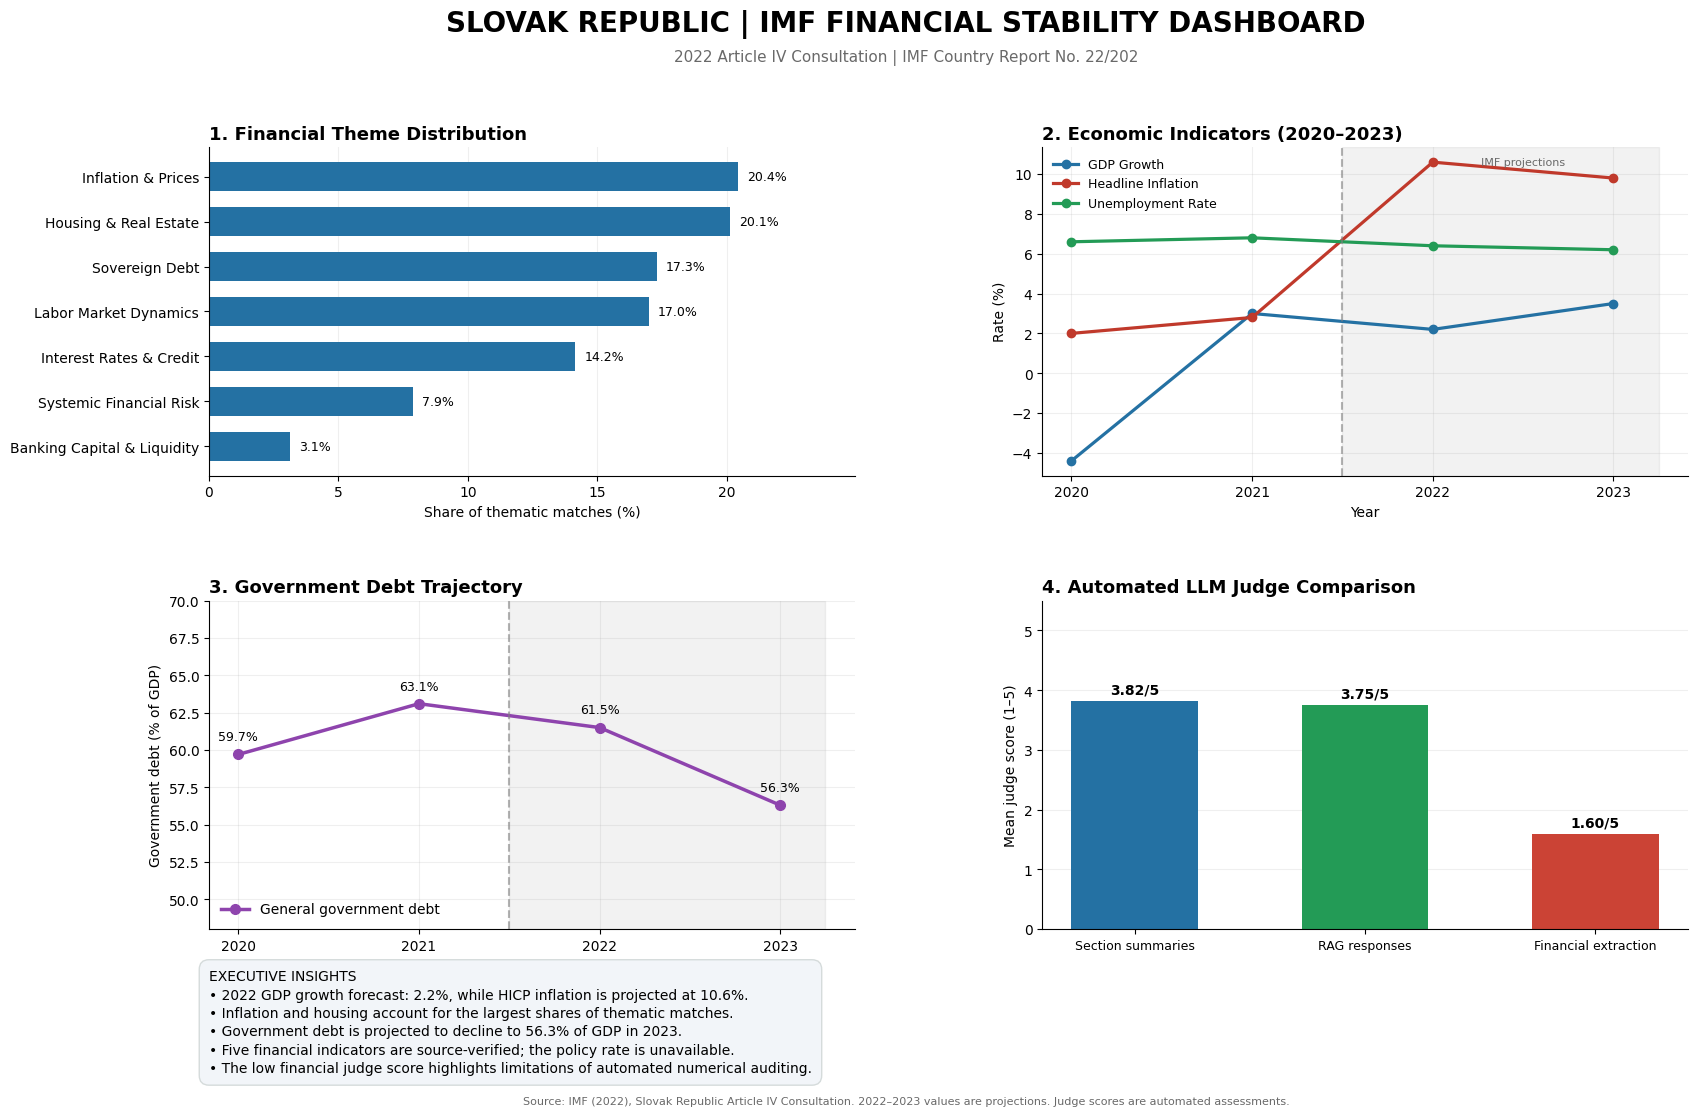

In [32]:

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Load saved project results
with open(output_dir / "slovakia_financial_themes.json") as f:
    theme_data = json.load(f)

trends = pd.read_csv(output_dir / "slovakia_economic_trends.csv")
summary_eval = pd.read_csv(output_dir / "slovakia_summary_evaluation.csv")
rag_eval = pd.read_csv(output_dir / "slovakia_rag_evaluation.csv")
financial_eval = pd.read_csv(output_dir / "slovakia_financial_evaluation.csv")

with open(output_dir / "slovakia_financial_data.json") as f:
    financial = json.load(f)

# Theme distribution
theme_df = pd.DataFrame([
    {"Theme": name, "Percentage": values["percentage"]}
    for name, values in theme_data.items()
]).sort_values("Percentage")

# Tidy economic trend data
trend_long = pd.melt(
    trends,
    id_vars="Year",
    var_name="Indicator",
    value_name="Value"
)

# Mean judge scores
judge_scores = pd.Series({
    "Section summaries": summary_eval[
        ["accuracy", "completeness", "consistency", "factual_alignment"]
    ].mean().mean(),
    "RAG responses": rag_eval[
        ["accuracy", "completeness", "faithfulness", "citation_quality"]
    ].mean().mean(),
    "Financial extraction": financial_eval[
        ["accuracy", "completeness", "consistency", "factual_alignment"]
    ].mean().mean()
})

# Dashboard style
plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.labelsize": 10,
    "figure.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False
})

fig, axes = plt.subplots(2, 2, figsize=(17, 11.5))
fig.subplots_adjust(
    left=0.09, right=0.96,
    top=0.85, bottom=0.17,
    hspace=0.38, wspace=0.29
)

fig.suptitle(
    "SLOVAK REPUBLIC | IMF FINANCIAL STABILITY DASHBOARD",
    fontsize=20, fontweight="bold", y=0.97
)

fig.text(
    0.5, 0.925,
    "2022 Article IV Consultation | IMF Country Report No. 22/202",
    ha="center", fontsize=11, color="dimgray"
)

# PANEL 1: Seven financial themes
ax = axes[0, 0]

bars = ax.barh(
    theme_df["Theme"],
    theme_df["Percentage"],
    color="#2471A3",
    height=0.65
)

ax.set_title("1. Financial Theme Distribution", fontweight="bold", loc="left")
ax.set_xlabel("Share of thematic matches (%)")
ax.set_xlim(0, max(theme_df["Percentage"]) * 1.22)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

for bar in bars:
    ax.text(
        bar.get_width() + 0.35,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.1f}%",
        va="center", fontsize=9
    )

# PANEL 2: Economic trends
ax = axes[0, 1]

trend_colors = {
    "GDP Growth": "#2471A3",
    "Headline Inflation": "#C0392B",
    "Unemployment Rate": "#239B56"
}

for name, color in trend_colors.items():
    data = trend_long[trend_long["Indicator"] == name]

    ax.plot(
        data["Year"], data["Value"],
        marker="o", linewidth=2.3,
        markersize=6, color=color, label=name
    )

ax.axvspan(2021.5, 2023.25, color="gray", alpha=0.10)
ax.axvline(2021.5, color="gray", linestyle="--", alpha=0.6)

ax.set_title("2. Economic Indicators (2020–2023)", fontweight="bold", loc="left")
ax.set_xlabel("Year")
ax.set_ylabel("Rate (%)")
ax.set_xticks([2020, 2021, 2022, 2023])
ax.legend(loc="upper left", fontsize=9, frameon=False)
ax.grid(alpha=0.2)

ax.text(
    2022.5, ax.get_ylim()[1] * 0.92,
    "IMF projections",
    ha="center", fontsize=8, color="dimgray"
)

# PANEL 3: Government debt
ax = axes[1, 0]

debt = trend_long[
    trend_long["Indicator"] == "Government Debt"
].sort_values("Year")

ax.plot(
    debt["Year"], debt["Value"],
    color="#8E44AD", marker="o",
    markersize=7, linewidth=2.5,
    label="General government debt"
)

ax.axvspan(2021.5, 2023.25, color="gray", alpha=0.10)
ax.axvline(2021.5, color="gray", linestyle="--", alpha=0.6)

for _, row in debt.iterrows():
    ax.annotate(
        f"{row['Value']:.1f}%",
        (row["Year"], row["Value"]),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center", fontsize=9
    )

ax.set_title("3. Government Debt Trajectory", fontweight="bold", loc="left")
ax.set_xlabel("Year")
ax.set_ylabel("Government debt (% of GDP)")
ax.set_xticks([2020, 2021, 2022, 2023])
ax.set_ylim(48, 70)
ax.legend(loc="lower left", frameon=False)
ax.grid(alpha=0.2)

# PANEL 4: Automated judge comparison
ax = axes[1, 1]

colors = ["#2471A3", "#239B56", "#CB4335"]

bars = ax.bar(
    judge_scores.index,
    judge_scores.values,
    color=colors, width=0.55
)

ax.set_title("4. Automated LLM Judge Comparison", fontweight="bold", loc="left")
ax.set_ylabel("Mean judge score (1–5)")
ax.set_ylim(0, 5.5)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.12,
        f"{bar.get_height():.2f}/5",
        ha="center", fontsize=10, fontweight="bold"
    )

ax.tick_params(axis="x", labelsize=9)

insight = (
    "EXECUTIVE INSIGHTS\n"
    "• 2022 GDP growth forecast: 2.2%, while HICP inflation is projected at 10.6%.\n"
    "• Inflation and housing account for the largest shares of thematic matches.\n"
    "• Government debt is projected to decline to 56.3% of GDP in 2023.\n"
    "• Five financial indicators are source-verified; the policy rate is unavailable.\n"
    "• The low financial judge score highlights limitations of automated numerical auditing."
)

fig.text(
    0.09, 0.135,
    insight,
    fontsize=10,
    va="top",
    linespacing=1.4,
    bbox={
        "boxstyle": "round,pad=0.7",
        "facecolor": "#F2F5F9",
        "edgecolor": "#D5DBDB"
    }
)

fig.text(
    0.5, 0.018,
    "Source: IMF (2022), Slovak Republic Article IV Consultation. "
    "2022–2023 values are projections. Judge scores are automated assessments.",
    ha="center", fontsize=8, color="dimgray"
)

dashboard_path = output_dir / "slovakia_imf_dashboard.png"

plt.savefig(
    dashboard_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

Project validation

In [33]:

import json
import pandas as pd
import faiss
from PIL import Image

required_files = [
    "slovakia_cleaned_pages.json",
    "slovakia_cleaned_text.txt",
    "slovakia_chunks.json",
    "slovakia_section_summaries.json",
    "slovakia_executive_summary.json",
    "slovakia_summary_evaluation.csv",
    "slovakia_financial_data.json",
    "slovakia_financial_audit.json",
    "slovakia_financial_validation.json",
    "slovakia_financial_themes.json",
    "slovakia_qualitative_insights.json",
    "slovakia_economic_trends.csv",
    "slovakia_economic_trends_long.csv",
    "slovakia_faiss.index",
    "slovakia_faiss_metadata.json",
    "slovakia_rag_audit.json",
    "slovakia_rag_evaluation.csv",
    "slovakia_financial_evaluation.csv",
    "slovakia_judge_comparison.csv",
    "slovakia_imf_dashboard.png"
]

missing = [
    name for name in required_files
    if not (output_dir / name).exists()
]

print("FINAL PROJECT VALIDATION")
print("\nRequired files:", len(required_files))
print("Files available:", len(required_files) - len(missing))
print("Missing files:", missing if missing else "None")

checks = {}

def load_json(name):
    with open(output_dir / name) as f:
        return json.load(f)

try:
    chunks_data = load_json("slovakia_chunks.json")
    checks["Token-aware chunks"] = (
        len(chunks_data) > 0
        and all(c["token_count"] <= 450 for c in chunks_data)
    )

    summaries = load_json("slovakia_section_summaries.json")
    checks["Seven section summaries"] = (
        len(summaries) == 7
        and all(
            0 < len(v["summary"].split()) < 100
            for v in summaries.values()
        )
    )

    executive = load_json("slovakia_executive_summary.json")
    checks["Executive summary"] = bool(
        executive.get("executive_summary", "").strip()
    )

    financial = load_json("slovakia_financial_data.json")
    required_indicators = [
        "gdp_growth_forecast_pct",
        "headline_inflation_rate_pct",
        "central_bank_policy_rate_pct",
        "non_performing_loan_ratio",
        "unemployment_rate_pct",
        "tier_1_capital_ratio"
    ]

    checks["Financial JSON schema"] = (
        financial.get("country_name") == "Slovak Republic"
        and all(k in financial for k in required_indicators)
        and all(
            financial[k] is None or
            (isinstance(financial[k], (int, float))
             and not isinstance(financial[k], bool))
            for k in required_indicators
        )
    )

    themes = load_json("slovakia_financial_themes.json")
    checks["Seven financial themes"] = len(themes) == 7

    qualitative = load_json("slovakia_qualitative_insights.json")
    checks["Qualitative insights"] = all(
        5 <= len(qualitative[k]) <= 7
        for k in ["strengths", "vulnerabilities"]
    )

    trends = pd.read_csv(output_dir / "slovakia_economic_trends.csv")
    checks["Four trend series"] = (
        len(trends) == 4
        and trends.shape[1] == 5
        and not trends.isna().any().any()
    )

    idx = faiss.read_index(str(output_dir / "slovakia_faiss.index"))
    checks["FAISS embedding index"] = (
        idx.ntotal == len(chunks_data) and idx.d > 0
    )

    rag = load_json("slovakia_rag_audit.json")
    checks["Four RAG responses"] = (
        len(rag) == 4
        and all(r.get("retrieved_context") for r in rag)
    )

    checks["Summary evaluation"] = (
        len(pd.read_csv(output_dir / "slovakia_summary_evaluation.csv")) == 7
    )

    checks["RAG evaluation"] = (
        len(pd.read_csv(output_dir / "slovakia_rag_evaluation.csv")) == 4
    )

    checks["Financial evaluation"] = (
        len(pd.read_csv(output_dir / "slovakia_financial_evaluation.csv")) == 6
    )

    with Image.open(output_dir / "slovakia_imf_dashboard.png") as img:
        dpi = img.info.get("dpi", (0, 0))
        checks["High-resolution dashboard"] = (
            img.width >= 3000
            and img.height >= 2000
            and min(dpi) >= 299
        )

except (FileNotFoundError, KeyError, ValueError,
        TypeError, json.JSONDecodeError) as e:
    print("\nValidation error:", e)

print("\nVALIDATION RESULTS\n")

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'REVIEW'}")

passed = sum(checks.values())

print("\nFINAL RESULT")
print("Checks passed:", passed, "/", len(checks))
print("Status:", "PASS" if not missing and
      len(checks) == 13 and all(checks.values())
      else "REVIEW REQUIRED")

FINAL PROJECT VALIDATION

Required files: 20
Files available: 20
Missing files: None

VALIDATION RESULTS

Token-aware chunks: PASS
Seven section summaries: PASS
Executive summary: PASS
Financial JSON schema: PASS
Seven financial themes: PASS
Qualitative insights: PASS
Four trend series: PASS
FAISS embedding index: PASS
Four RAG responses: PASS
Summary evaluation: PASS
RAG evaluation: PASS
Financial evaluation: PASS
High-resolution dashboard: PASS

FINAL RESULT
Checks passed: 13 / 13
Status: PASS
